# Reporte 1 Python: visualización de una serie de tiempo

## 1. Identificación
**Nombre completo:** Francisca Montes

**Código de la serie:** F049.DES.TAS.INE9.10.M  
**Variable:** Tasa de desocupación, total | No ajustada | INE | Mensual | Porcentaje  
**Descripción:** La serie representa la tasa mensual de desocupación total informada por el INE, expresada en porcentaje y sin ajuste estacional.


## 2. Importación de bibliotecas


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


## 3. Carga del archivo

Antes de ejecutar esta sección, subir el archivo Tasas_desocupacion.xlsx al almacenamiento de sesión de Google Colab, como se pidio en las instrucciones y utilizar su Ruta de acceso.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

ruta = "/content/Tasas_desocupacion.xlsx"

df = pd.read_excel(ruta)

df.head()

,"Fecha,Valor"
0,"2020-01-01,7.4430743295789"
1,"2020-02-01,7.8105192968302"
2,"2020-03-01,8.2285090973616"
3,"2020-04-01,9.0018555844912"
4,"2020-05-01,11.206932833479"


In [ ]:
df = df.iloc[:, 0].str.split(",", expand=True)

df.columns = ["Fecha", "Valor"]

df.head()

,Fecha,Valor
0,2020-01-01,7.4430743295789
1,2020-02-01,7.8105192968302
2,2020-03-01,8.2285090973616
3,2020-04-01,9.0018555844912
4,2020-05-01,11.206932833479


## 4. Exploración de los datos


In [ ]:
print('Primeras cinco observaciones:')
display(df.head())

print('\nNombre de las columnas:')
print(df.columns.tolist())

print('\nCantidad de filas y columnas:')
print(df.shape)

print('\nTipos de datos:')
print(df.dtypes)

print('\nValores faltantes por columna:')
print(df.isna().sum())


Primeras cinco observaciones:


,Fecha,Valor
0,2020-01-01,7.4430743295789
1,2020-02-01,7.8105192968302
2,2020-03-01,8.2285090973616
3,2020-04-01,9.0018555844912
4,2020-05-01,11.206932833479



Nombre de las columnas:
['Fecha', 'Valor']

Cantidad de filas y columnas:
(78, 2)

Tipos de datos:
Fecha    object
Valor    object
dtype: object

Valores faltantes por columna:
Fecha    0
Valor    0
dtype: int64


## 5. Preparación de la serie


In [ ]:
df['Fecha'] = pd.to_datetime(df['Fecha'], errors='coerce')  #Convertir la fecha a formato datetime

df['Valor'] = pd.to_numeric(df['Valor'], errors='coerce')  # Convertir los valores de la serie a formato numérico

df = df.sort_values('Fecha').reset_index(drop=True)  # Ordenar cronológicamente

print('Tipos de datos después de la preparación:')
print(df.dtypes)

print('\nValores faltantes después de la conversión:')
print(df.isna().sum())

display(df.head())


Tipos de datos después de la preparación:
Fecha    datetime64[ns]
Valor           float64
dtype: object

Valores faltantes después de la conversión:
Fecha    0
Valor    0
dtype: int64


,Fecha,Valor
0,2020-01-01,7.443074
1,2020-02-01,7.810519
2,2020-03-01,8.228509
3,2020-04-01,9.001856
4,2020-05-01,11.206933


### Revisión de valores extremos


In [ ]:
maximo = df.loc[df['Valor'].idxmax(), ['Fecha', 'Valor']]
minimo = df.loc[df['Valor'].idxmin(), ['Fecha', 'Valor']]

print('Máximo de la serie:')
print(maximo)
print('\nMínimo de la serie:')
print(minimo)


Máximo de la serie:
Fecha    2020-07-01 00:00:00
Valor              13.091216
Name: 6, dtype: object

Mínimo de la serie:
Fecha    2021-12-01 00:00:00
Valor               7.189893
Name: 23, dtype: object


## 6. Elaboración del gráfico


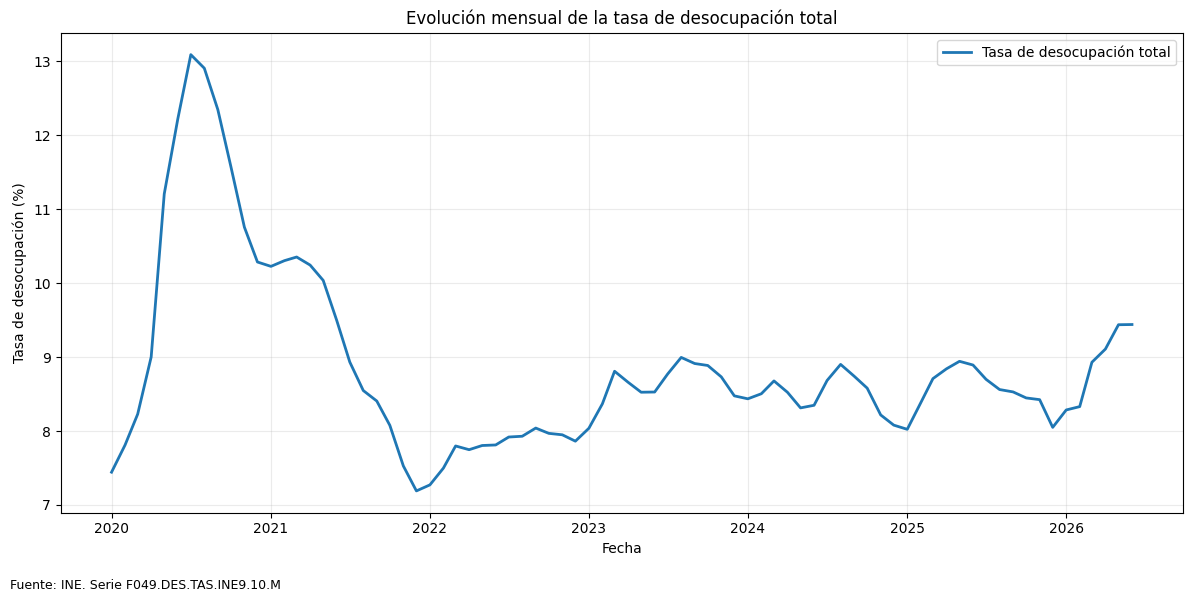

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    df['Fecha'],
    df['Valor'],
    linewidth=2,
    label='Tasa de desocupación total'
)

ax.set_title('Evolución mensual de la tasa de desocupación total')
ax.set_xlabel('Fecha')
ax.set_ylabel('Tasa de desocupación (%)')
ax.legend()
ax.grid(alpha=0.25)

fig.text(
    0.01, 0.01,
    'Fuente: INE. Serie F049.DES.TAS.INE9.10.M',
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()


## 7. Interpretación

La tasa de desocupación muestra una fuerte alza durante 2020, pasando desde cerca de 7,4% en enero hasta un máximo de 13,1% en julio. Posteriormente, la serie inicia una tendencia descendente que se mantiene durante 2021 y alcanza su nivel mínimo, cercano a 7,2%, en diciembre de ese año. Durante 2022 la tasa se mantiene relativamente baja, pero desde 2023 vuelve a aumentar y luego presenta fluctuaciones moderadas en torno a 8%–9%. En 2024 y 2025 no se observa una tendencia sostenida, sino variaciones mensuales acotadas. Hacia 2026 aparece un nuevo aumento, superando 9% desde abril y llegando aproximadamente a 9,4% en mayo y junio. En síntesis, la serie presenta un shock muy marcado en 2020, una recuperación posterior y un repunte gradual al final del período.